# Parte 0 – Contextualización y sincronización

Adquisición con la Muse (4 canales secos, 256 Hz), visualización de los canales, sesiones según `tags.csv`, bloques de 1-back/3-back según `n_back_responses.csv`, verificación de la sincronización y desempeño por sesión.

Se trabaja primero con el sujeto **B1** (experimento 2) y al final se repite el resumen para todos los sujetos descargados (en particular **A9**, el que analiza el artículo para el experimento 1).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from eeg_nback import datos
from eeg_nback.config import load_config
from eeg_nback.filtrado import mascara_saturacion

cfg = load_config()
FS = cfg['FS']
CANALES = cfg['CANALES']

## 1. Adquisición de la señal

- **Equipo:** vincha Muse, EEG portátil de **electrodos secos** (sin gel). Por eso la impedancia electrodo-piel es más alta y variable que en un equipo clínico, y la señal es más sensible a movimiento y mal contacto.
- **Montaje:** 4 canales en posiciones del sistema 10-20 extendido: **TP9** y **TP10** (temporoparietales, detrás de las orejas) y **AF7** y **AF8** (frontales, en la frente). El quinto canal del archivo, `Right AUX`, no se usa.
- **Referencia:** los cuatro canales se miden respecto de un electrodo de referencia ubicado en la frente (Fpz).
- **Muestreo:** $f_s = 256$ Hz, amplitud en µV y una marca de tiempo UNIX por muestra.

Por el teorema de muestreo, con $f_s = 256$ Hz se puede representar sin aliasing el contenido hasta la frecuencia de Nyquist $f_s/2 = 128$ Hz. Las bandas de interés (hasta beta, 30 Hz) y la interferencia de línea (60 Hz) quedan por debajo.

In [3]:
print(f"Frecuencia de muestreo: {FS} Hz  ->  Nyquist: {FS / 2:.0f} Hz")
print(f"Período de muestreo: {1000 / FS:.2f} ms")

Frecuencia de muestreo: 256 Hz  ->  Nyquist: 128 Hz
Período de muestreo: 3.91 ms


## 2. Sujetos disponibles

In [4]:
sujetos = datos.listar_sujetos()
sujetos

,experimento,sujeto,ruta,tiene_eeg
0,1,A1,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True
1,1,A2,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True
2,1,A3,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True
3,1,A4,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True
4,1,A5,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True
5,1,A6,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True
6,1,A7,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True
7,1,A8,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True
8,1,A9,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True
9,1,A10,C:\PSIB\TPS\PSIB_TPS_GRUPO_13\data\raw\Experim...,True


## 3. Carga del EEG del sujeto B1

In [5]:
s = sujetos.query("sujeto == 'B1'").iloc[0]

t, eeg = datos.cargar_eeg(s.ruta)          # hora UNIX de cada muestra, DataFrame en µV
nback = datos.cargar_nback(s.ruta)         # un estímulo por fila
bloques = datos.tabla_bloques(nback)       # un bloque por fila
sesiones = datos.tabla_sesiones(s.ruta, nback)

print(f"{len(t)} muestras, {(t[-1] - t[0]) / 60:.1f} min de registro")
eeg.describe().round(1)

1440660 muestras, 93.8 min de registro


,TP9,AF7,AF8,TP10
count,1440660.0,1440660.0,1440660.0,1440660.0
mean,38.1,0.5,36.2,35.0
std,104.1,271.4,29.8,72.2
min,-1000.0,-1000.0,-999.0,-1000.0
25%,17.1,-109.4,23.9,25.4
50%,42.0,27.3,36.1,37.6
75%,66.9,129.9,47.9,51.8
max,999.5,999.5,999.5,999.5


### 3.1 Verificación de la frecuencia de muestreo

Los timestamps de la Muse están redondeados al milisegundo, así que el intervalo entre muestras consecutivas vale 3 o 4 ms (el período real es 3,906 ms). Por eso $f_s$ no se estima muestra a muestra sino como cantidad de muestras sobre duración total. También se buscan **huecos** (intervalos mucho mayores que el período), que indicarían pérdida de datos.

In [6]:
dt_ms = np.diff(t) * 1000
print(f"fs estimada = (N - 1) / duración = {(len(t) - 1) / (t[-1] - t[0]):.2f} Hz")
print("Intervalos entre muestras (ms, redondeados):")
print(pd.Series(np.round(dt_ms)).value_counts().sort_index().to_string())
print(f"Intervalo máximo: {dt_ms.max():.0f} ms")

fs estimada = (N - 1) / duración = 256.00 Hz
Intervalos entre muestras (ms, redondeados):
3.0     135062
4.0    1305597
Intervalo máximo: 4 ms


## 4. Visualización de los canales

Registro completo de cada canal, con las sesiones marcadas según `tags.csv`.

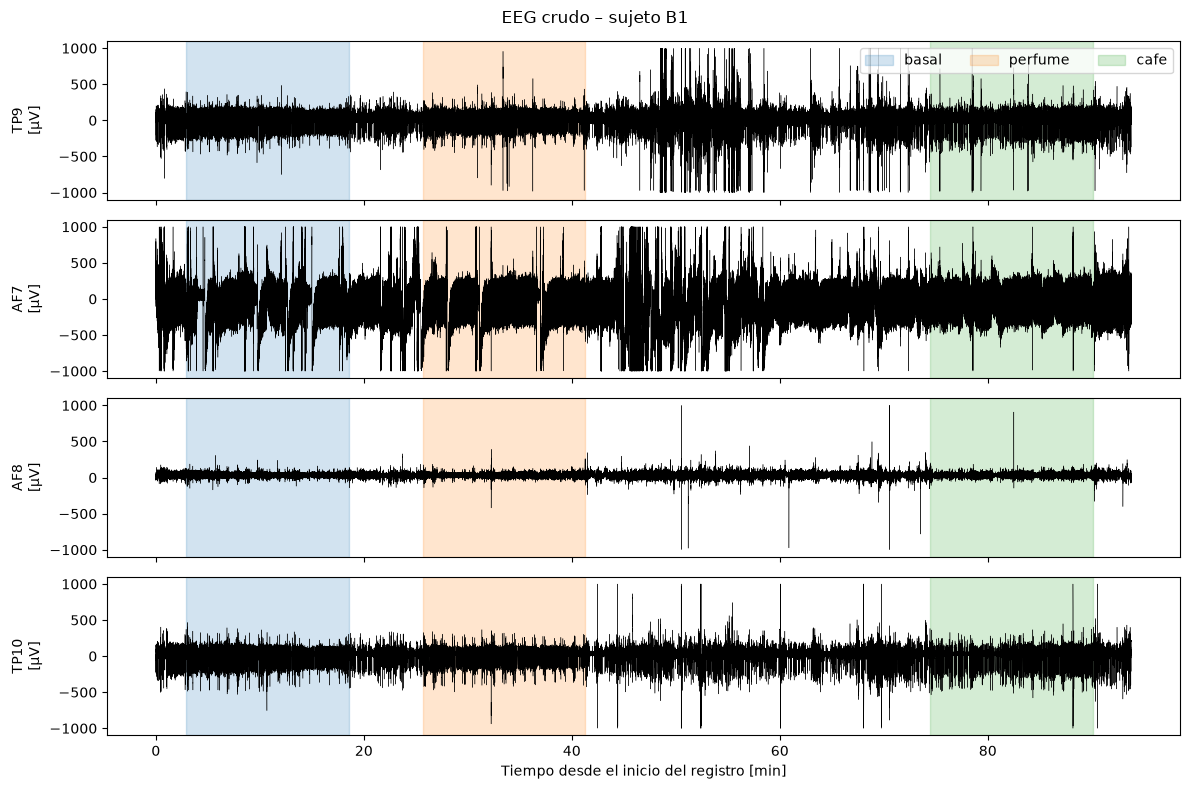

In [7]:
t_min = (t - t[0]) / 60
colores_ses = plt.cm.tab10.colors

fig, axs = plt.subplots(len(CANALES), 1, sharex=True, figsize=(12, 8))
for ax, c in zip(axs, CANALES):
    ax.plot(t_min, eeg[c], lw=0.3, color='k')
    for i, r in enumerate(sesiones.itertuples()):
        ax.axvspan((r.tag_ini - t[0]) / 60, (r.tag_fin - t[0]) / 60,
                   color=colores_ses[i], alpha=0.2, label=r.condicion)
    ax.set_ylabel(f'{c}\n[µV]')
axs[0].legend(loc='upper right', ncol=len(sesiones))
axs[-1].set_xlabel('Tiempo desde el inicio del registro [min]')
fig.suptitle(f'EEG crudo – sujeto {s.sujeto}')
plt.tight_layout()

Detalle de 10 s dentro del primer bloque de la primera sesión:

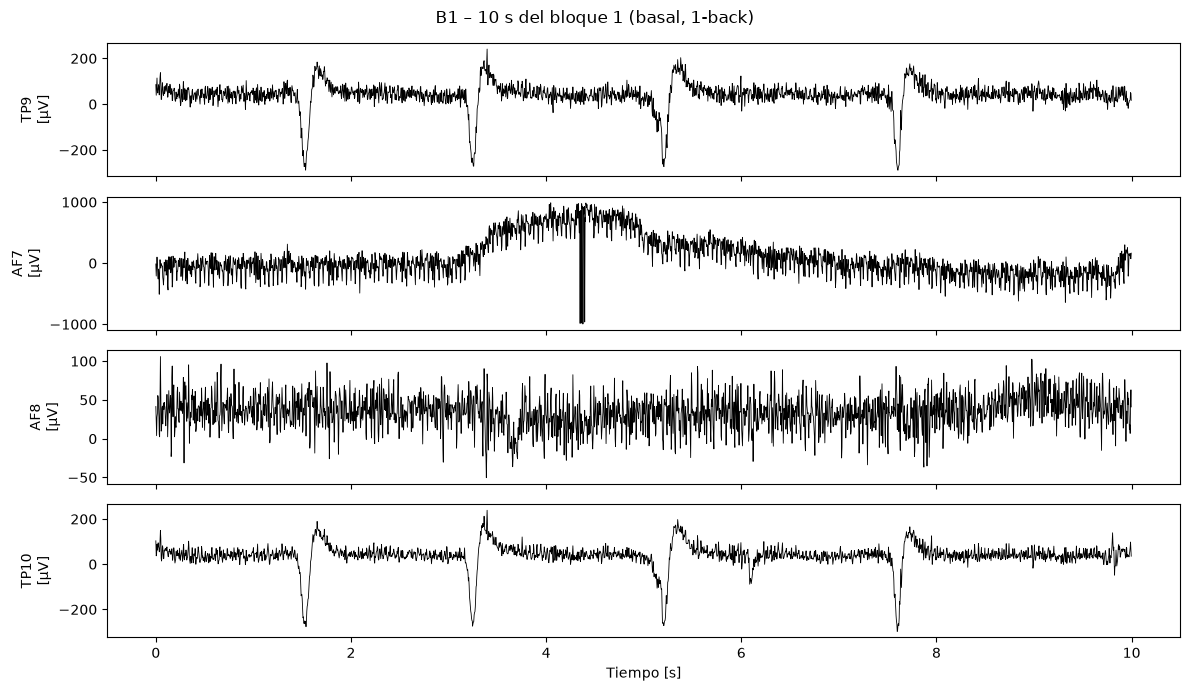

In [8]:
b0 = bloques.iloc[0]
tz, xz = datos.recortar(t, eeg, b0.t_ini, b0.t_ini + 10)

fig, axs = plt.subplots(len(CANALES), 1, sharex=True, figsize=(12, 7))
for ax, c in zip(axs, CANALES):
    ax.plot(tz - tz[0], xz[c], lw=0.6, color='k')
    ax.set_ylabel(f'{c}\n[µV]')
axs[-1].set_xlabel('Tiempo [s]')
fig.suptitle(f'{s.sujeto} – 10 s del bloque 1 ({b0.condicion}, {b0.tipo})')
plt.tight_layout()

### 4.1 Muestras saturadas

La Muse satura en ±1000 µV. Se calcula el porcentaje de muestras saturadas por canal y sesión (se usan después en la Parte 2 para descartar épocas).

In [9]:
def pct_saturadas(t, eeg, sesiones):
    filas = {}
    for r in sesiones.itertuples():
        _, x = datos.recortar(t, eeg, r.tag_ini, r.tag_fin)
        filas[r.condicion] = mascara_saturacion(x).mean(axis=0) * 100
    return pd.DataFrame(filas, index=CANALES).T

pct_saturadas(t, eeg, sesiones).round(2)

,TP9,AF7,AF8,TP10
basal,0.00,0.78,0.0,0.00
perfume,0.00,0.60,0.0,0.00
cafe,0.01,0.04,0.0,0.05


## 5. Separación por sesión (`tags.csv`)

`tags.csv` tiene dos marcas por sesión (inicio y fin). Para verificar la sincronización entre el reloj de la vincha y el de la computadora que corre la tarea (E-Prime), se comprueba que todos los estímulos de cada sesión caigan dentro de sus tags, y que el EEG cubra todas las sesiones.

In [10]:
ses = sesiones.copy()
ses['duracion_tags_min'] = (ses.tag_fin - ses.tag_ini) / 60
ses['tarea_min'] = (ses.ultimo_estimulo - ses.primer_estimulo) / 60
ses['margen_ini_s'] = ses.primer_estimulo - ses.tag_ini
ses['margen_fin_s'] = ses.tag_fin - ses.ultimo_estimulo
ses[['sesion', 'condicion', 'duracion_tags_min', 'tarea_min', 'margen_ini_s', 'margen_fin_s', 'dentro']].round(1)

,sesion,condicion,duracion_tags_min,tarea_min,margen_ini_s,margen_fin_s,dentro
0,1,basal,15.6,15.1,21.9,12.4,True
1,2,perfume,15.5,15.1,13.3,11.7,True
2,3,cafe,15.7,15.3,15.5,12.8,True


In [11]:
print(f"El EEG empieza {sesiones.tag_ini.min() - t[0]:.1f} s antes del primer tag")
print(f"y termina {t[-1] - sesiones.tag_fin.max():.1f} s después del último.")

El EEG empieza 174.8 s antes del primer tag
y termina 218.6 s después del último.


### 5.1 Caso particular: al sujeto A8 le falta un tag

> ## Aviso: tag estimado en el sujeto A8 (sesión 2, música relajante)
>
> **Qué pasa:** cada sesión debería tener dos marcas en `tags.csv` (inicio y fin), así que A8, con 4 sesiones, debería tener 8. **Tiene 7: falta el inicio de la sesión 2.** Es un defecto del archivo del dataset, no de la descarga ni del código: el EEG y las respuestas de la tarea de A8 están completos.
>
> **Por qué no se descarta al sujeto:** el objetivo del trabajo es analizar la totalidad de los sujetos válidos y el artículo lo considera válido. El tag solo sirve para delimitar la sesión; los bloques de la tarea (que son los que se analizan) se ubican con la hora de cada estímulo en `n_back_responses.csv`, que sí está completa.
>
> **Qué se hizo:**
> 1. Los tags se asignan a cada sesión **por su hora** y no de a pares (`datos.tabla_sesiones`): el inicio de una sesión es el último tag libre antes de su primer estímulo y el fin es el primer tag libre después de su último estímulo. Con los otros 19 sujetos el resultado es idéntico al de tomarlos de a pares.
> 2. El inicio que falta se **estima** como el primer estímulo de la sesión menos **11,8 s**, que es la **mediana** del margen entre el tag de inicio y el primer estímulo en las 66 sesiones que tienen sus dos tags (19 sujetos). Se eligió la mediana y no la media (17,4 s) porque hay sesiones con márgenes de hasta 90 s que desplazan la media.
> 3. La sesión queda marcada con `tag_ini_estimado = True`.
>
> **Alternativa descartada:** usar como inicio el fin de la sesión 1. Ese tramo incluiría unos 200 s de descanso entre sesiones, que no pertenecen a la sesión 2.
>
> **Consecuencias:**
> - Para esa sesión, la verificación de que "los estímulos caen dentro de los tags" **se cumple por construcción y no verifica nada** al comienzo de la sesión (el fin sí es un tag real).
> - Lo que cambia es solo dónde empieza el tramo previo al primer bloque: el margen inicial de esa sesión es de 11,8 s, dentro del rango observado en las demás (6,0 a 90,6 s), y alcanza para la convergencia del LMS y los bordes del filtrado (Parte 1).
> - Los resultados de A8 – sesión 2 se informan con esta aclaración.

In [12]:
a8 = sujetos.query("sujeto == 'A8'")
if len(a8):
    ruta_a8 = a8.iloc[0].ruta
    tags_a8 = datos.cargar_tags(ruta_a8)
    print(f"A8: {len(tags_a8)} tags para {datos.cargar_nback(ruta_a8).sesion.nunique()} sesiones\n")
    ses_a8 = datos.tabla_sesiones(ruta_a8)
    t0_a8 = tags_a8[0]
    mostrar = ses_a8.copy()
    for col in ['tag_ini', 'primer_estimulo', 'ultimo_estimulo', 'tag_fin']:
        mostrar[col] = mostrar[col] - t0_a8
    print("Tiempos en segundos desde el primer tag:")
    display(mostrar[['sesion', 'condicion', 'tag_ini', 'primer_estimulo', 'ultimo_estimulo', 'tag_fin',
                     'tag_ini_estimado', 'tag_fin_estimado']].round(1))
else:
    print("A8 no está descargado.")

A8: 7 tags para 4 sesiones



Tiempos en segundos desde el primer tag:


,sesion,condicion,tag_ini,primer_estimulo,ultimo_estimulo,tag_fin,tag_ini_estimado,tag_fin_estimado
0,1,sin_musica,0.0,31.7,965.2,982.6,False,False
1,2,relajante,1167.4,1179.2,2115.2,2133.0,True,False
2,3,estimulante,2500.8,2510.9,3425.7,3441.1,False,False
3,4,ia,3631.3,3642.2,4559.3,4577.1,False,False


## 6. Separación en bloques (`n_back_responses.csv`)

Cada sesión tiene bloques de 22 estímulos. Cada estímulo dura 500 ms y le sigue una cruz de fijación de 1500 ms, así que un bloque dura unos 22 × 2 s = 44 s. Entre bloques hay una pausa (reposo). Se verifica la cantidad de bloques de cada tipo, su duración y la duración de las pausas.

In [13]:
bloques['duracion_s'] = bloques.t_fin - bloques.t_ini
bloques['pausa_siguiente_s'] = bloques.groupby('sesion').t_ini.shift(-1) - bloques.t_fin

print("Bloques por sesión y tipo:")
print(bloques.groupby(['sesion', 'condicion', 'tipo']).size().unstack().to_string())
print()
print("Estímulos por bloque:", bloques.n_estimulos.unique())
bloques[['duracion_s', 'pausa_siguiente_s']].describe().round(1)

Bloques por sesión y tipo:
tipo              1-back  3-back
sesion condicion                
1      basal           8       8
2      perfume         8       8
3      cafe            8       8

Estímulos por bloque: [22]


,duracion_s,pausa_siguiente_s
count,48.0,45.0
mean,42.7,15.1
std,0.5,0.7
min,41.5,14.9
25%,42.4,14.9
50%,42.8,15.0
75%,43.1,15.0
max,43.8,18.1


Primera sesión con los bloques marcados sobre un canal: en gris claro las pausas (reposo).

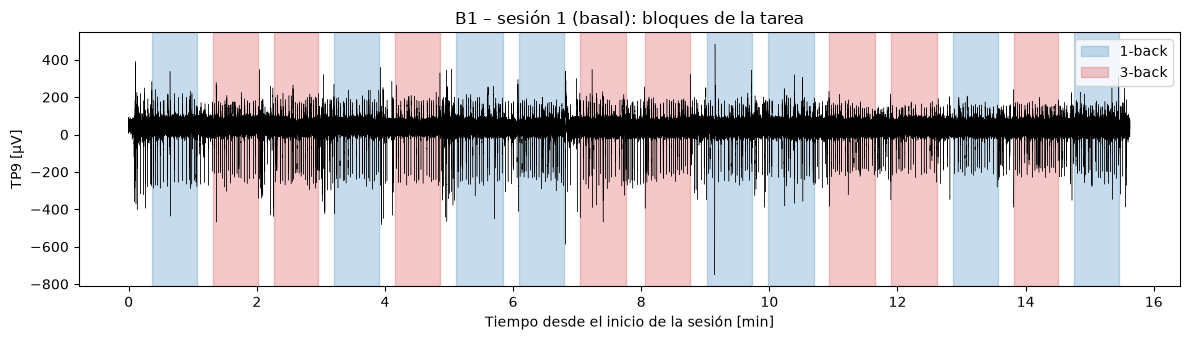

In [14]:
r = sesiones.iloc[0]
ts, xs = datos.recortar(t, eeg['TP9'], r.tag_ini, r.tag_fin)
color_tipo = {'1-back': 'tab:blue', '3-back': 'tab:red'}

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot((ts - r.tag_ini) / 60, xs, lw=0.3, color='k')
for b in bloques[bloques.sesion == r.sesion].itertuples():
    ax.axvspan((b.t_ini - r.tag_ini) / 60, (b.t_fin - r.tag_ini) / 60,
               color=color_tipo[b.tipo], alpha=0.25)
ax.legend(handles=[Patch(color=col, alpha=0.25, label=tipo) for tipo, col in color_tipo.items()],
          loc='upper right')
ax.set_xlabel('Tiempo desde el inicio de la sesión [min]')
ax.set_ylabel('TP9 [µV]')
ax.set_title(f'{s.sujeto} – sesión {r.sesion} ({r.condicion}): bloques de la tarea')
plt.tight_layout()

## 7. Desempeño en la tarea

Porcentaje de aciertos y mediana del tiempo de reacción (en los estímulos en que el sujeto respondió), por sesión y tipo de n-back.

In [15]:
def desempeno(nback):
    orden = nback.condicion.unique()
    d = (nback.groupby(['condicion', 'tipo'])
              .agg(aciertos_pct=('acierto', 'mean'), rt_mediana_ms=('rt', 'median'))
              .reindex(orden, level=0))
    d['aciertos_pct'] *= 100
    return d

d = desempeno(nback)
d.round(1)

aciertos_pct  rt_mediana_ms
condicion tipo                               
basal     1-back          92.6          381.0
          3-back          88.6          398.0
perfume   1-back          93.8          387.5
          3-back          87.5          413.0
cafe      1-back          94.9          415.0
          3-back          81.2          450.0

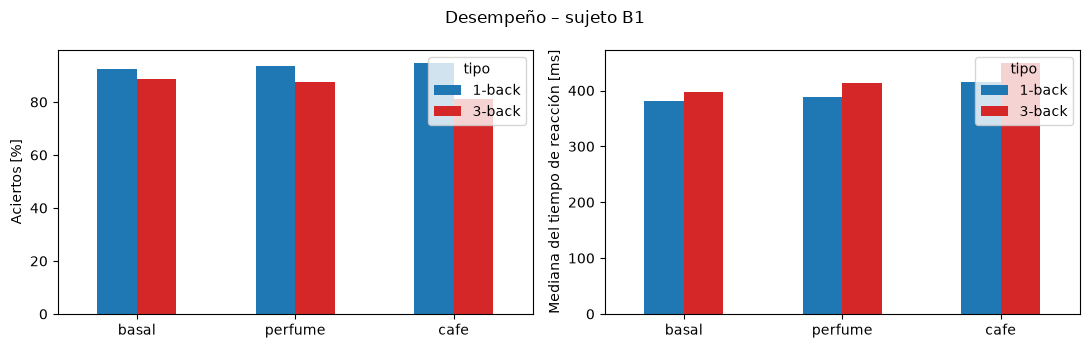

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
d.aciertos_pct.unstack().plot.bar(ax=axs[0], color=color_tipo, rot=0)
axs[0].set_ylabel('Aciertos [%]')
d.rt_mediana_ms.unstack().plot.bar(ax=axs[1], color=color_tipo, rot=0)
axs[1].set_ylabel('Mediana del tiempo de reacción [ms]')
for ax in axs:
    ax.set_xlabel('')
fig.suptitle(f'Desempeño – sujeto {s.sujeto}')
plt.tight_layout()

## 8. Verificación de todos los sujetos

El análisis se hace sobre la totalidad de los sujetos válidos (A1–A10 y B1–B10). Para cada uno se repiten las verificaciones hechas con B1:

- **Muestreo:** $f_s$ estimada como (N − 1) / duración e intervalo máximo entre muestras (huecos).
- **Sincronización:** que los estímulos de cada sesión caigan dentro de sus tags y que el EEG cubra todas las sesiones.
- **Bloques:** cantidad de bloques de cada tipo por sesión, estímulos por bloque, duración de bloques y pausas.
- **Calidad del canal:** porcentaje de muestras saturadas y desvío estándar de cada canal dentro de las sesiones.

In [17]:
verif, calidad, bloques_todos, nback_todos = [], [], [], []

for suj in sujetos.itertuples():
    t_s, eeg_s = datos.cargar_eeg(suj.ruta)
    nb_s = datos.cargar_nback(suj.ruta)
    ses_s = datos.tabla_sesiones(suj.ruta, nb_s)
    bl_s = datos.tabla_bloques(nb_s)
    bl_s['duracion_s'] = bl_s.t_fin - bl_s.t_ini
    bl_s['pausa_siguiente_s'] = bl_s.groupby('sesion').t_ini.shift(-1) - bl_s.t_fin
    conteo = bl_s.groupby(['sesion', 'tipo']).size().unstack()

    verif.append({
        'sujeto': suj.sujeto,
        'n_sesiones': len(ses_s),
        'fs_estimada': (len(t_s) - 1) / (t_s[-1] - t_s[0]),
        'dt_max_ms': np.diff(t_s).max() * 1000,
        'estimulos_en_tags': ses_s.dentro.all(),
        'eeg_cubre_sesiones': (t_s[0] <= ses_s.tag_ini.min()) and (t_s[-1] >= ses_s.tag_fin.max()),
        'tags_estimados': int(ses_s.tag_ini_estimado.sum() + ses_s.tag_fin_estimado.sum()),
        'bloques_1back_por_sesion': sorted(conteo['1-back'].unique()),
        'bloques_3back_por_sesion': sorted(conteo['3-back'].unique()),
        'estimulos_por_bloque': sorted(bl_s.n_estimulos.unique()),
        'dur_bloque_s': bl_s.duracion_s.median(),
        'pausa_s': bl_s.pausa_siguiente_s.median(),
    })

    for r in ses_s.itertuples():
        _, x = datos.recortar(t_s, eeg_s, r.tag_ini, r.tag_fin)
        for c in CANALES:
            calidad.append({'sujeto': suj.sujeto, 'condicion': r.condicion, 'canal': c,
                            'pct_saturadas': mascara_saturacion(x[c]).mean() * 100,
                            'desvio_uV': x[c].std()})

    bloques_todos.append(bl_s.assign(sujeto=suj.sujeto))
    nback_todos.append(nb_s.assign(sujeto=suj.sujeto))

verif = pd.DataFrame(verif)
calidad = pd.DataFrame(calidad)
bloques_todos = pd.concat(bloques_todos, ignore_index=True)
nback_todos = pd.concat(nback_todos, ignore_index=True)
verif.round(2)

,sujeto,n_sesiones,fs_estimada,dt_max_ms,estimulos_en_tags,eeg_cubre_sesiones,tags_estimados,bloques_1back_por_sesion,bloques_3back_por_sesion,estimulos_por_bloque,dur_bloque_s,pausa_s
0,A1,4,256.0,4.0,True,True,0,[8],[8],[22],41.18,14.87
1,A2,4,256.0,4.0,True,True,0,[8],[8],[22],43.42,15.00
2,A3,4,256.2,4.0,True,True,0,[8],[8],[22],43.24,14.98
3,A4,4,256.0,4.0,True,True,0,[8],[8],[22],44.00,15.02
4,A5,4,256.2,4.0,True,True,0,[8],[8],[22],43.88,15.01
5,A6,4,256.0,4.0,True,True,0,[8],[8],[22],44.26,15.01
6,A7,4,256.0,4.0,True,True,0,[8],[8],[22],42.20,14.91
7,A8,4,256.0,4.0,True,True,1,[8],[8],[22],43.53,15.01
8,A9,4,256.0,4.0,True,True,0,[8],[8],[22],43.40,14.98
9,A10,4,256.2,4.0,True,True,0,[8],[8],[22],44.26,15.02


In [18]:
print(f"Sujetos verificados: {len(verif)}")
print(f"Con estímulos fuera de los tags: {(~verif.estimulos_en_tags).sum()}")
print(f"Con EEG que no cubre las sesiones: {(~verif.eeg_cubre_sesiones).sum()}")
print(f"Con tags estimados (ver 5.1): {list(verif.sujeto[verif.tags_estimados > 0])}")
print(f"Con huecos (intervalo > 10 ms): {(verif.dt_max_ms > 10).sum()}")
print()
print("Duración de bloques y pausas (todos los sujetos):")
bloques_todos[['duracion_s', 'pausa_siguiente_s']].describe().round(1)

Sujetos verificados: 20
Con estímulos fuera de los tags: 0
Con EEG que no cubre las sesiones: 0
Con tags estimados (ver 5.1): ['A8']
Con huecos (intervalo > 10 ms): 0

Duración de bloques y pausas (todos los sujetos):


,duracion_s,pausa_siguiente_s
count,1120.0,1050.0
mean,43.4,15.6
std,0.9,2.8
min,40.5,14.5
25%,43.0,15.0
50%,43.8,15.0
75%,44.2,15.0
max,44.3,30.1


### 8.1 Calidad de cada canal

Porcentaje de muestras saturadas y desvío estándar de cada canal, por sujeto (promedio entre sesiones).

In [19]:
cal_suj = calidad.groupby(['sujeto', 'canal'], sort=False)[['pct_saturadas', 'desvio_uV']].mean().unstack('canal')
cal_suj = cal_suj.reindex(sujetos.sujeto)
cal_suj.round(2)

pct_saturadas                   desvio_uV                        
canal            TP9   AF7   AF8  TP10       TP9     AF7     AF8    TP10
sujeto                                                                  
A1              0.14  0.24  0.20  0.25     86.06  101.75   81.68   92.56
A2              0.00  0.01  0.00  0.00     78.03   28.37   29.50   82.03
A3              0.02  0.00  0.01  0.01     35.24   13.05   21.19   36.69
A4              0.00  0.14  0.01  0.00     45.82  261.84   24.42   38.55
A5              0.00  0.03  0.09  0.01     37.41   37.85   50.40   34.93
A6              0.00  0.02  0.00  0.00     39.39   20.58   16.20   41.10
A7              0.00  0.05  0.04  0.00     69.11   39.08   43.06   70.77
A8              0.05  0.01  0.02  0.03     68.35   34.62   37.78   62.60
A9              0.04  0.03  0.14  7.37     80.02   39.35  205.31  584.53
A10             0.00  0.02  0.06  0.00     39.83   25.21   38.54   38.27
B1              0.00  0.47  0.00  0.02     68.59  225.41   21.76   62.89
B2              0.00  0.00  0.01  0.01     29.73   15.37   22.09   37.01
B3              0.00  0.01  0.00  0.00     48.22   31.83   31.59   49.46
B4              0.03  0.08  0.04  0.01     42.63   59.94   42.69   31.59
B5              0.00  1.53  0.03  0.00     39.52  272.27   29.31   39.01
B6              0.02  0.02  0.02  0.05     55.54   43.18   38.34   59.22
B7              0.07  0.16  0.15  0.08     71.27   75.07   72.98   73.55
B8              0.00  0.00  0.00  0.00     61.36   23.27   22.91   62.76
B9              0.01  0.01  0.02  0.01     46.38   20.88   25.17   47.51
B10             0.00  0.00  0.00  0.01     53.71   26.71   27.70   60.62

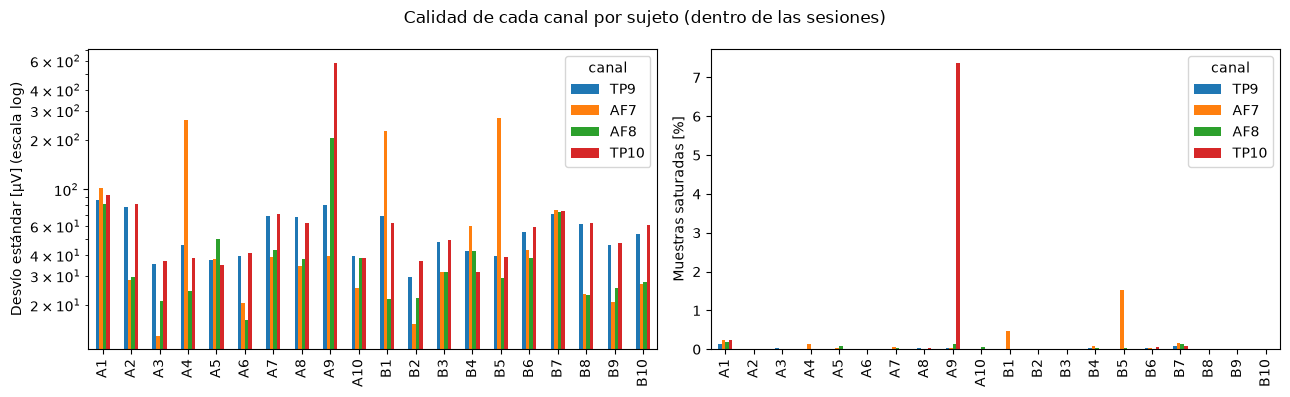

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
cal_suj['desvio_uV'][CANALES].plot.bar(ax=axs[0], logy=True, rot=90)
axs[0].set_ylabel('Desvío estándar [µV] (escala log)')
cal_suj['pct_saturadas'][CANALES].plot.bar(ax=axs[1], rot=90)
axs[1].set_ylabel('Muestras saturadas [%]')
for ax in axs:
    ax.set_xlabel('')
fig.suptitle('Calidad de cada canal por sujeto (dentro de las sesiones)')
plt.tight_layout()

### 8.2 Desempeño de todos los sujetos

Porcentaje de aciertos por sujeto, sesión y tipo de n-back.

In [21]:
aciertos = (nback_todos.groupby(['sujeto', 'condicion', 'tipo'], sort=False).acierto.mean() * 100).unstack('tipo')
aciertos['diferencia_1menos3'] = aciertos['1-back'] - aciertos['3-back']
aciertos.round(1)

tipo                1-back  3-back  diferencia_1menos3
sujeto condicion                                      
A1     sin_musica     98.3    94.3                 4.0
       relajante      97.2    93.2                 4.0
       estimulante    97.2    84.1                13.1
       ia             98.3    91.5                 6.8
A2     sin_musica     92.0    84.7                 7.4
...                    ...     ...                 ...
B9     perfume        90.3    76.7                13.6
       cafe           89.8    68.8                21.0
B10    basal          90.3    73.9                16.5
       perfume        94.9    86.4                 8.5
       cafe           92.6    79.0                13.6

[70 rows x 3 columns]

Sesiones en que 3-back tuvo menos aciertos que 1-back: 69 de 70


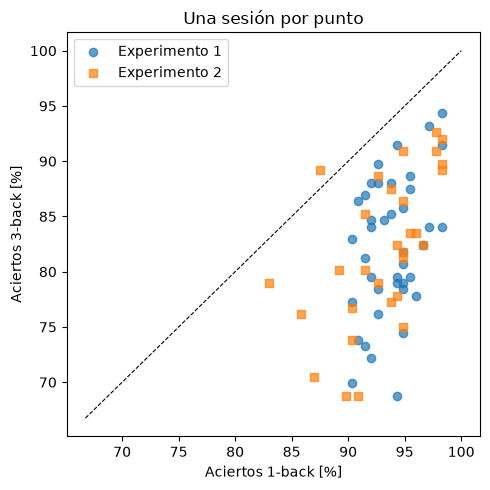

In [22]:
print(f"Sesiones en que 3-back tuvo menos aciertos que 1-back: "
      f"{(aciertos.diferencia_1menos3 > 0).sum()} de {len(aciertos)}")

fig, ax = plt.subplots(figsize=(5, 5))
for exp, marca in [('A', 'o'), ('B', 's')]:
    a = aciertos[aciertos.index.get_level_values('sujeto').str.startswith(exp)]
    ax.scatter(a['1-back'], a['3-back'], marker=marca, alpha=0.7, label=f'Experimento {1 if exp == "A" else 2}')
lim = [aciertos[['1-back', '3-back']].min().min() - 2, 100]
ax.plot(lim, lim, 'k--', lw=0.8)
ax.set_xlabel('Aciertos 1-back [%]')
ax.set_ylabel('Aciertos 3-back [%]')
ax.set_title('Una sesión por punto')
ax.legend()
plt.tight_layout()

## 9. Conclusiones

Verificación sobre los **20 sujetos** (A1–A10 y B1–B10); el análisis en detalle de las secciones 3 a 7 corresponde a B1.

1. **Muestreo:** en los 20 sujetos la frecuencia de muestreo estimada es 256 Hz (entre 256,0 y 256,2 Hz) y el intervalo máximo entre muestras es de 4 ms: ningún registro tiene huecos. Los intervalos valen 3 o 4 ms porque los timestamps están redondeados al milisegundo (período real 3,906 ms).
2. **Sincronización:** en todos los sujetos los estímulos de cada sesión caen dentro de sus tags y el EEG cubre todas las sesiones, así que cada tramo de EEG se puede asignar a su sesión y bloque. **Excepción: a A8 le falta el tag de inicio de la sesión 2**, que se estimó (sección 5.1); para esa sesión la verificación del inicio no es posible.
3. **Bloques:** todas las sesiones tienen 8 bloques de 1-back y 8 de 3-back, de 22 estímulos cada uno, de 43,4 ± 0,9 s. Las pausas entre bloques duran entre 14,5 y 16 s (983 de 1050), salvo la pausa que sigue al bloque 8 (mitad de la sesión), que dura entre 16 y 30 s en 67 de las 70 sesiones. El anteproyecto indica pausas de 10 s: el valor medido en los datos es mayor.
4. **Calidad de la señal:**
   - Hay canales con un desvío estándar mucho mayor que el resto: **A9 – TP10** (585 µV, con 7,4 % de muestras saturadas), **A9 – AF8** (205 µV), y **AF7 en A4, B1 y B5** (225–272 µV, B5 con 1,5 % de muestras saturadas). En los demás canales el desvío está entre 13 y 102 µV y las muestras saturadas son menos del 0,3 %.
   - En B1 se observan además deflexiones negativas de unos −250 µV, simultáneas en TP9 y TP10 y repetidas cada ~2 s, y artefactos muy grandes entre sesiones (fuera de los tags, no se usan).
   - Estas observaciones se cuantifican en la Parte 2 (artefactos y rechazo de épocas) antes de decidir si se usa cada canal. Es especialmente importante para **A9**, el sujeto que analiza el artículo, porque los canales temporales son los que el artículo usa para la banda beta.
5. **Desempeño:** el porcentaje de aciertos es menor en 3-back que en 1-back en **69 de las 70 sesiones** (la excepción es B6, sesión basal: 89,2 % frente a 87,5 %). Mediana de aciertos: 94 % en 1-back y 82–83 % en 3-back en ambos experimentos. Esto es coherente con que el 3-back impone una carga cognitiva mayor; la comparación estadística se hace en la Parte 5.